# Results -- HTR Error Dataset evaluation

Aggregates the raw per-system predictions written by `evaluate.py`
(`results/predictions/*.csv`) into headline metrics, figures, and summary
tables. Run `evaluate.py` for at least one system before running this
notebook -- see README.md.

Core measurements:
- **CER** (character error rate) on clean vs. corrupted images.
- **Faithful rate**: share of corrupted-image predictions that match the
  text actually displayed (the corrupted word) -- faithful visual
  grounding.
- **Repair rate**: share of corrupted-image predictions that instead match
  the *original*, uncorrupted word -- the system "fixed" an implausible
  stimulus using a linguistic prior instead of reading what is on the
  page.
- **Minimal-pair effect**: whether repair is more frequent when the
  corruption happens to land on another real word.


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))
from plotting import apply_style, style_ax, save_fig, BLUE, ORANGE, AQUA, RED, VIOLET, GREEN, INK_MUTED
from textmetrics import levenshtein, normalize_prediction, load_english_wordset
from systems import SYSTEMS_BY_NAME, PROMPT_VARIANTS

apply_style()

DATASET_DIR = Path("dataset")
PRED_DIR = Path("results/predictions")
RESULTS_DIR = Path("results")
FIG_DIR = Path("results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

DEFAULT_VARIANT = "default"  # a system's own configured prompt (systems.py)
VARIANT_COLOR = {DEFAULT_VARIANT: BLUE, "diplomatic": ORANGE, "symbol_game": AQUA}
VARIANT_LABEL = {
    DEFAULT_VARIANT: "Own default prompt",
    "diplomatic": "Diplomatic-transcription prompt",
    "symbol_game": "Symbol-game prompt",
}


## 1. Load predictions and ground truth

In [2]:
def parse_pred_filename(path: Path) -> tuple[str, str]:
    """'<system>.csv' -> (system, 'default'); '<system>__<variant>.csv' -> (system, variant)."""
    stem = path.stem
    if "__" in stem:
        system, variant = stem.split("__", 1)
        return system, variant
    return stem, DEFAULT_VARIANT


def load_predictions() -> pd.DataFrame:
    frames = []
    found_systems = set()
    for path in sorted(PRED_DIR.glob("*.csv")):
        system, variant = parse_pred_filename(path)
        if system not in SYSTEMS_BY_NAME:
            print(f"WARNING: {path} doesn't match a known system name -- skipped")
            continue
        df = pd.read_csv(path, dtype={"id": str})
        if df.empty:
            continue
        df["system"] = system
        df["variant"] = variant
        frames.append(df)
        found_systems.add(system)
    missing = sorted(set(SYSTEMS_BY_NAME) - found_systems)
    for name in missing:
        print(f"WARNING: no predictions for {name} -- skipped")
    if not frames:
        raise SystemExit("No prediction files found in results/predictions/. Run evaluate.py first.")
    return pd.concat(frames, ignore_index=True)


meta = pd.read_csv(DATASET_DIR / "metadata.csv", dtype={"id": str})
wordset = load_english_wordset()
meta["word_is_dict"] = meta["word"].str.lower().isin(wordset)
meta["error_is_dict"] = meta["error_word"].str.lower().isin(wordset)
meta["minimal_pair"] = meta["word_is_dict"] & meta["error_is_dict"]

raw_preds = load_predictions()
print(f"{len(raw_preds)} raw prediction rows, systems: {sorted(raw_preds['system'].unique())}")


47856 raw prediction rows, systems: ['deepseek_ocr', 'glm_4_6v', 'glm_4_6v_flash', 'kraken', 'lightonocr_1b', 'olmocr_2_7b', 'qwen3_vl_2b', 'qwen3_vl_30b_a3b', 'qwen3_vl_8b', 'tesseract']


## 2. Score every prediction

In [3]:
def score(preds: pd.DataFrame, meta: pd.DataFrame) -> pd.DataFrame:
    preds = preds.copy()
    preds["pred_norm"] = [
        normalize_prediction(p, SYSTEMS_BY_NAME[s].cleanup)
        for p, s in zip(preds["prediction"], preds["system"])
    ]
    preds["gt_norm"] = preds["gt_text"].str.lower()
    preds = preds.merge(meta[["id", "word", "error_word", "minimal_pair"]], on="id", how="left")

    preds["cer"] = [
        levenshtein(p, g) / max(1, len(g)) for p, g in zip(preds["pred_norm"], preds["gt_norm"])
    ]
    preds["exact_match"] = preds["pred_norm"] == preds["gt_norm"]
    preds["repaired_to_original"] = False
    err_mask = preds["condition"] == "error"
    preds.loc[err_mask, "repaired_to_original"] = (
        preds.loc[err_mask, "pred_norm"] == preds.loc[err_mask, "word"].str.lower()
    )
    return preds


preds = score(raw_preds, meta)
preds.to_csv(RESULTS_DIR / "predictions_scored.csv", index=False)
preds.head()


,id,condition,image_path,gt_text,prediction,elapsed_sec,system,variant,pred_norm,gt_norm,word,error_word,minimal_pair,cer,exact_match,repaired_to_original
0,g04-039_00001,clean,dataset/images/g04-039_00001_clean.png,house,housée,0.242,deepseek_ocr,default,hous,house,house,douse,True,0.200000,False,False
1,g04-039_00001,error,dataset/images/g04-039_00001_error.png,douse,doule,0.149,deepseek_ocr,default,doule,douse,house,douse,True,0.200000,False,False
2,g04-039_00002,clean,dataset/images/g04-039_00002_clean.png,not,\[n 0 . 5\],0.168,deepseek_ocr,default,n,not,not,aot,False,0.666667,False,False
3,g04-039_00002,error,dataset/images/g04-039_00002_error.png,aot,\( 0 . 0 5 \),0.171,deepseek_ocr,default,,aot,not,aot,False,1.000000,False,False
4,g04-039_00003,clean,dataset/images/g04-039_00003_clean.png,and,\[ \sin \theta \],0.165,deepseek_ocr,default,,and,and,ant,True,1.000000,False,False


## 3. Summarize per (system, prompt variant)

In [4]:
def summarize(preds: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for (system, variant), sub in preds.groupby(["system", "variant"]):
        spec = SYSTEMS_BY_NAME[system]
        clean = sub[sub["condition"] == "clean"]
        error = sub[sub["condition"] == "error"]
        mp_error = error[error["minimal_pair"]]
        nonmp_error = error[~error["minimal_pair"]]
        rows.append({
            "system": system,
            "variant": variant,
            "display_name": spec.display_name,
            "kind": spec.kind,
            "n_clean": len(clean),
            "n_error": len(error),
            "cer_clean": clean["cer"].mean(),
            "cer_error": error["cer"].mean(),
            "cer_paired_increase": error["cer"].mean() - clean["cer"].mean(),
            "word_acc_clean": clean["exact_match"].mean(),
            "faithful_rate_error": error["exact_match"].mean(),
            "repair_rate_error": error["repaired_to_original"].mean(),
            "faithful_rate_minimal_pair": mp_error["exact_match"].mean() if len(mp_error) else float("nan"),
            "repair_rate_minimal_pair": mp_error["repaired_to_original"].mean() if len(mp_error) else float("nan"),
            "faithful_rate_non_minimal_pair": nonmp_error["exact_match"].mean() if len(nonmp_error) else float("nan"),
            "mean_latency_sec": sub["elapsed_sec"].mean(),
        })
    return pd.DataFrame(rows)


all_summary = summarize(preds)
all_summary.to_csv(RESULTS_DIR / "metrics_summary_variants.csv", index=False)

summary = all_summary[all_summary["variant"] == DEFAULT_VARIANT].sort_values("cer_error")
summary.to_csv(RESULTS_DIR / "metrics_summary.csv", index=False)
summary


,system,variant,display_name,kind,n_clean,n_error,cer_clean,cer_error,cer_paired_increase,word_acc_clean,faithful_rate_error,repair_rate_error,faithful_rate_minimal_pair,repair_rate_minimal_pair,faithful_rate_non_minimal_pair,mean_latency_sec
3,glm_4_6v,default,GLM-4.6V,vlm,997,997,0.019575,0.135712,0.116137,0.942828,0.654965,0.054162,0.775701,0.037383,0.621967,0.383521
6,glm_4_6v_flash,default,GLM-4.6V-Flash,vlm,997,997,0.028954,0.141971,0.113018,0.920762,0.626881,0.046138,0.757009,0.023364,0.591315,0.205694
20,qwen3_vl_8b,default,Qwen3-VL-8B-Instruct,vlm,997,997,0.026128,0.199630,0.173501,0.945838,0.521565,0.096289,0.705607,0.032710,0.471264,0.262951
11,olmocr_2_7b,default,olmOCR-2-7B,vlm,997,997,0.032665,0.212528,0.179863,0.928786,0.483450,0.102307,0.686916,0.042056,0.427842,0.190391
17,qwen3_vl_30b_a3b,default,Qwen3-VL-30B-A3B-Instruct,vlm,997,997,0.033735,0.228108,0.194374,0.933801,0.444333,0.103310,0.654206,0.042056,0.386973,0.184452
14,qwen3_vl_2b,default,Qwen3-VL-2B-Instruct,vlm,997,997,0.052324,0.295563,0.243239,0.908726,0.414243,0.070211,0.565421,0.018692,0.372925,0.091208
10,lightonocr_1b,default,LightOnOCR-1B,vlm,997,997,0.065379,0.320741,0.255361,0.883651,0.371113,0.127382,0.579439,0.056075,0.314176,0.082520
23,tesseract,default,Tesseract v5,traditional,997,997,0.507296,0.591262,0.083966,0.256770,0.129388,0.014042,0.224299,0.004673,0.103448,0.054792
0,deepseek_ocr,default,DeepSeek-OCR,vlm,997,997,0.572124,0.665133,0.093010,0.184554,0.096289,0.013039,0.107477,0.004673,0.093231,0.165506
9,kraken,default,Kraken (Rev City English HTR),traditional,997,997,0.591491,0.739237,0.147746,0.172518,0.025075,0.029087,0.051402,0.023364,0.017880,0.010511


In [5]:
variant_summary = all_summary[all_summary["variant"] != DEFAULT_VARIANT]
if not variant_summary.empty:
    print("--- prompt-variant runs ---")
    display(variant_summary.sort_values(["system", "variant"]))
else:
    print("No prompt-variant runs found (results/predictions/<system>__<variant>.csv).")


--- prompt-variant runs ---


,system,variant,display_name,kind,n_clean,n_error,cer_clean,cer_error,cer_paired_increase,word_acc_clean,faithful_rate_error,repair_rate_error,faithful_rate_minimal_pair,repair_rate_minimal_pair,faithful_rate_non_minimal_pair,mean_latency_sec
1,deepseek_ocr,diplomatic,DeepSeek-OCR,vlm,997,997,0.975121,0.963779,-0.011341,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.166053
2,deepseek_ocr,symbol_game,DeepSeek-OCR,vlm,997,997,0.932693,0.924385,-0.008308,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.328326
4,glm_4_6v,diplomatic,GLM-4.6V,vlm,997,997,0.031729,0.166175,0.134446,0.923771,0.619860,0.025075,0.747664,0.018692,0.584930,0.742456
5,glm_4_6v,symbol_game,GLM-4.6V,vlm,997,997,0.029923,0.141458,0.111535,0.923771,0.653962,0.023069,0.766355,0.014019,0.623244,0.729977
7,glm_4_6v_flash,diplomatic,GLM-4.6V-Flash,vlm,997,997,0.041995,0.166213,0.124218,0.903711,0.596790,0.029087,0.714953,0.018692,0.564496,0.411458
8,glm_4_6v_flash,symbol_game,GLM-4.6V-Flash,vlm,997,997,0.036937,0.145135,0.108198,0.906720,0.622869,0.031093,0.733645,0.018692,0.592593,0.436537
12,olmocr_2_7b,diplomatic,olmOCR-2-7B,vlm,997,997,0.039719,0.214214,0.174495,0.913741,0.512538,0.061184,0.691589,0.032710,0.463602,0.363981
13,olmocr_2_7b,symbol_game,olmOCR-2-7B,vlm,997,997,0.037446,0.182552,0.145107,0.905717,0.540622,0.055165,0.705607,0.032710,0.495530,0.367918
15,qwen3_vl_2b,diplomatic,Qwen3-VL-2B-Instruct,vlm,997,997,0.117620,0.383207,0.265587,0.793380,0.337011,0.021063,0.387850,0.000000,0.323116,0.129890
16,qwen3_vl_2b,symbol_game,Qwen3-VL-2B-Instruct,vlm,997,997,0.058743,0.248085,0.189342,0.881645,0.458375,0.035105,0.560748,0.009346,0.430396,0.147246


## 4. Figures

### 4.1 Character error rate: clean vs. corrupted


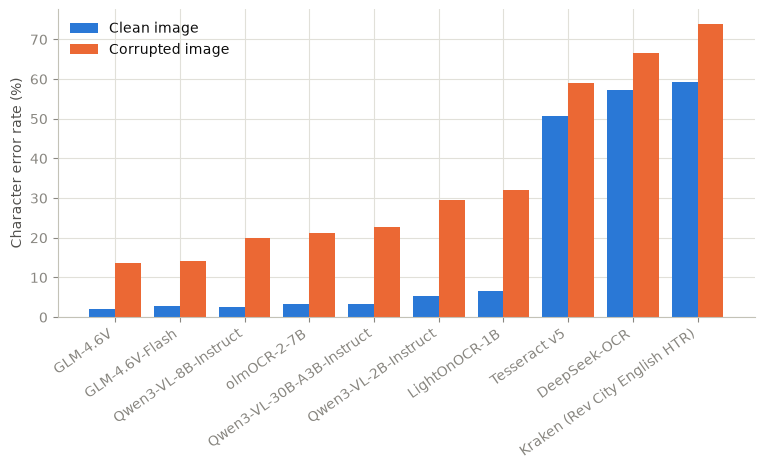

In [6]:
s = summary.sort_values("cer_error")
x = np.arange(len(s))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - 0.2, s["cer_clean"] * 100, width=0.4, color=BLUE, label="Clean image")
ax.bar(x + 0.2, s["cer_error"] * 100, width=0.4, color=ORANGE, label="Corrupted image")
ax.set_xticks(x)
ax.set_xticklabels(s["display_name"], rotation=35, ha="right")
style_ax(ax)
ax.legend(frameon=False)
ax.set_ylabel("Character error rate (%)")
save_fig(fig, "results_fig1_cer_clean_vs_error", FIG_DIR)
plt.show()


### 4.2 Faithful vs. repair rate on corrupted images

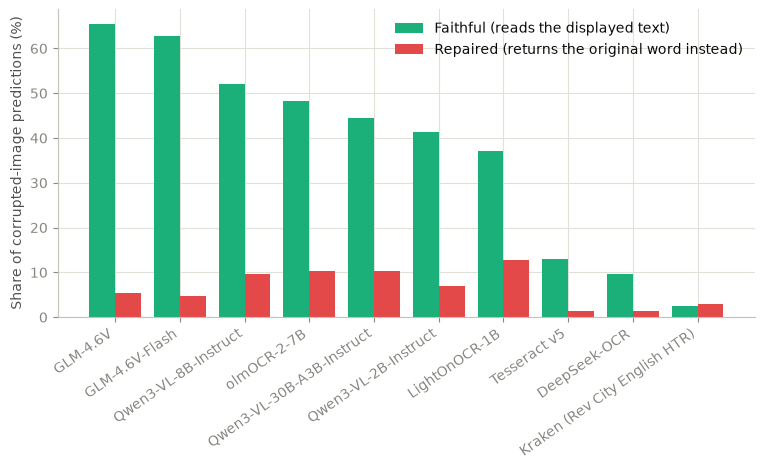

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - 0.2, s["faithful_rate_error"] * 100, width=0.4, color=AQUA,
       label="Faithful (reads the displayed text)")
ax.bar(x + 0.2, s["repair_rate_error"] * 100, width=0.4, color=RED,
       label="Repaired (returns the original word instead)")
ax.set_xticks(x)
ax.set_xticklabels(s["display_name"], rotation=35, ha="right")
style_ax(ax)
ax.legend(frameon=False)
ax.set_ylabel("Share of corrupted-image predictions (%)")
save_fig(fig, "results_fig2_faithful_vs_repair", FIG_DIR)
plt.show()


### 4.3 Minimal-pair effect

Repair rate when the corruption happens to land on another real English
word (e.g. *said* -> *laid*) versus the faithful rate on corruptions that
are not real words. A higher repair rate on minimal pairs indicates
stronger linguistic-prior reliance.


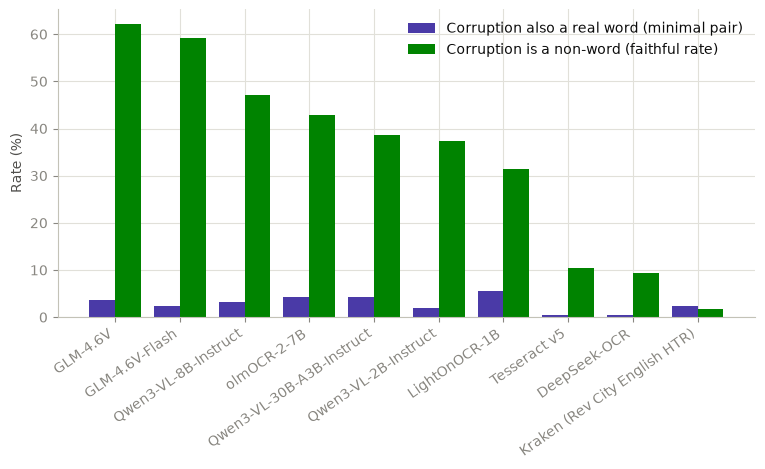

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - 0.2, s["repair_rate_minimal_pair"] * 100, width=0.4, color=VIOLET,
       label="Corruption also a real word (minimal pair)")
ax.bar(x + 0.2, s["faithful_rate_non_minimal_pair"] * 100, width=0.4, color=GREEN,
       label="Corruption is a non-word (faithful rate)")
ax.set_xticks(x)
ax.set_xticklabels(s["display_name"], rotation=35, ha="right")
style_ax(ax)
ax.legend(frameon=False)
ax.set_ylabel("Rate (%)")
save_fig(fig, "results_fig3_minimal_pair_effect", FIG_DIR)
plt.show()


### 4.4 Prompt-variant comparison

Only produced for systems that have at least one non-default prompt
variant recorded (i.e. `evaluate.py` was run with `--prompt-variant`).


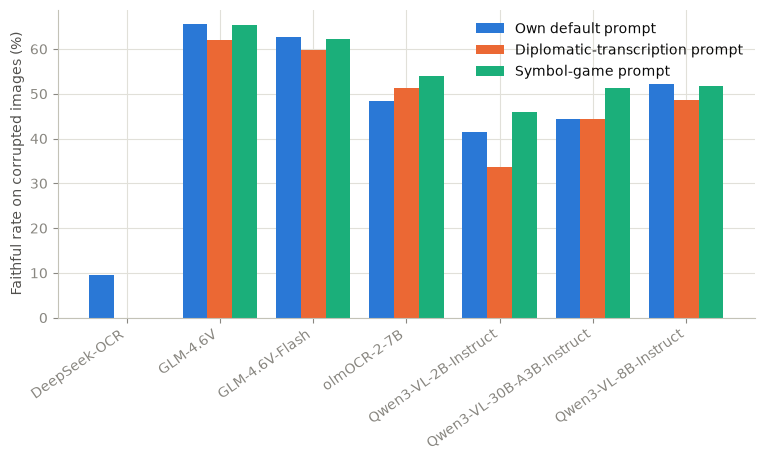

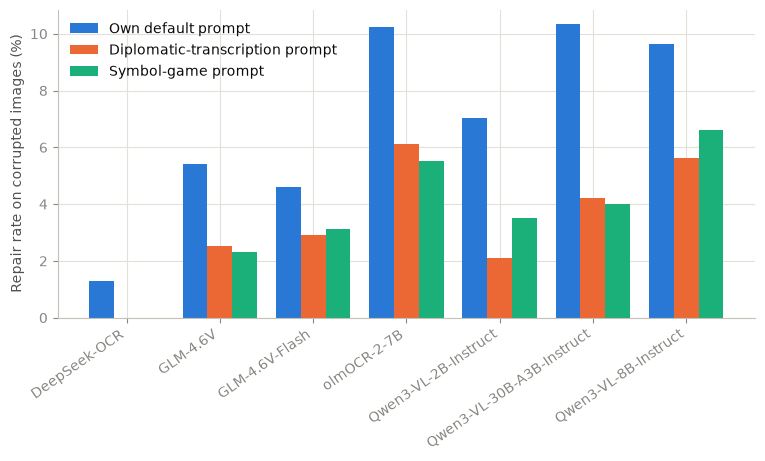

In [9]:
systems_with_variants = sorted(
    all_summary.loc[all_summary["variant"] != DEFAULT_VARIANT, "system"].unique()
)

if not systems_with_variants:
    print("No prompt-variant runs found -- skipping.")
else:
    variants_present = [DEFAULT_VARIANT] + [v for v in PROMPT_VARIANTS if
                                             (all_summary["variant"] == v).any()]
    vs = all_summary[all_summary["system"].isin(systems_with_variants)]
    display_names = [SYSTEMS_BY_NAME[sv].display_name for sv in systems_with_variants]
    xv = np.arange(len(systems_with_variants))
    width = 0.8 / len(variants_present)

    for metric, fname, ylabel in [
        ("faithful_rate_error", "results_fig4_prompt_variants_faithful", "Faithful rate on corrupted images (%)"),
        ("repair_rate_error", "results_fig5_prompt_variants_repair", "Repair rate on corrupted images (%)"),
    ]:
        fig, ax = plt.subplots(figsize=(9, 4))
        for i, variant in enumerate(variants_present):
            vals = []
            for sysname in systems_with_variants:
                row = vs[(vs["system"] == sysname) & (vs["variant"] == variant)]
                vals.append(row[metric].iloc[0] * 100 if len(row) else np.nan)
            offset = (i - (len(variants_present) - 1) / 2) * width
            ax.bar(xv + offset, vals, width=width, color=VARIANT_COLOR.get(variant, INK_MUTED),
                   label=VARIANT_LABEL.get(variant, variant))
        ax.set_xticks(xv)
        ax.set_xticklabels(display_names, rotation=35, ha="right")
        style_ax(ax)
        ax.legend(frameon=False)
        ax.set_ylabel(ylabel)
        save_fig(fig, fname, FIG_DIR)
        plt.show()


## 5. Headline summary

In [10]:
def _fmt_pct(x):
    return f"{x*100:.1f}%" if pd.notna(x) else "--"


best_faithful = s.loc[s["faithful_rate_error"].idxmax()]
worst_faithful = s.loc[s["faithful_rate_error"].idxmin()]
highest_repair = s.loc[s["repair_rate_error"].idxmax()]

print(f"Most faithful on corrupted images:  {best_faithful['display_name']} "
      f"({_fmt_pct(best_faithful['faithful_rate_error'])} exact match)")
print(f"Least faithful on corrupted images: {worst_faithful['display_name']} "
      f"({_fmt_pct(worst_faithful['faithful_rate_error'])} exact match)")
print(f"Strongest repair behaviour:         {highest_repair['display_name']} "
      f"({_fmt_pct(highest_repair['repair_rate_error'])} of corrupted trials "
      f"returned the ORIGINAL word instead of the one actually shown)")

n_pairs = preds["id"].nunique()
total_dataset_n = len(meta)
if n_pairs < total_dataset_n:
    print(f"\nNote: this is a partial run ({n_pairs} of {total_dataset_n} dataset pairs). "
          f"Re-run evaluate.py --system all over the full dataset before treating these "
          f"numbers as final.")

print(f"\nWrote {RESULTS_DIR/'metrics_summary.csv'}, "
      f"{RESULTS_DIR/'metrics_summary_variants.csv'}, "
      f"{RESULTS_DIR/'predictions_scored.csv'}, and figures in {FIG_DIR}/")


Most faithful on corrupted images:  GLM-4.6V (65.5% exact match)
Least faithful on corrupted images: Kraken (Rev City English HTR) (2.5% exact match)
Strongest repair behaviour:         LightOnOCR-1B (12.7% of corrupted trials returned the ORIGINAL word instead of the one actually shown)

Wrote results/metrics_summary.csv, results/metrics_summary_variants.csv, results/predictions_scored.csv, and figures in results/figures/
